# Nose occupancy: slide figures

Presentation versions of the figures in `occupancy_nose.ipynb`, which stays the in-house reference (unsmoothed maps, mouse IDs). Here:

- **Maps are smoothed** with a Gaussian of `SMOOTH_BINS` bins (1 bin = a quarter of a target cell, about 44 px). Smoothing is applied to each session's relative-occupancy map, so every mean and difference map below is built from smoothed sessions. The numbers (zone shares, similarity, the wall profile) are computed from the **unsmoothed** maps, exactly as in the original notebook, so they match it.
- **Mice are named Mouse 1-9**, in order of ID; the key is printed below the setup cell.
- **Bounds are drawn explicitly**: the camera frame, the edge of the 3 x 9 target grid, the target cells, and the middle row.
- Each figure is sized for a 16:9 slide and saved to `output/slides/` as PNG.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import ndimage

from src import config as cfg
from src.trials import load_trials
from src.epochs import EPOCHS
from src.occupancy import load_occupancy, X_EDGES, Y_EDGES     # run `python -m src.occupancy` to rebuild output/occupancy*.npz

EXPERIMENTS = ['odor', 'vision']
EXP_LABEL = {'odor': 'Odor', 'vision': 'Vision'}
from src.style import INK, MUTED, GRID, PAPER, SLIDE, use_style
PAD = 1.25                                            # scales every gap between panels and every margin around them
use_style(slides=True)
SLIDES_DIR = cfg.OUT_DIR / 'slides'
SLIDES_DIR.mkdir(exist_ok=True)

POINT = 'nose'
SMOOTH_BINS = 1                                       # Gaussian sigma, in bins

loaded = [load_occupancy(e, POINT) for e in EXPERIMENTS]
ses = pd.concat([l[0] for l in loaded], ignore_index=True)
maps = {epoch: np.concatenate([l[1][epoch] for l in loaded]) for epoch in EPOCHS}     # {epoch: [session, y bin, x bin]}, seconds

def density(maps):
    """Share of time per bin, scaled so 1 = time spread evenly over the arena."""
    return maps / maps.sum(axis=(-2, -1), keepdims=True) * maps.shape[-2] * maps.shape[-1]

def smooth(m):
    """Gaussian smoothing over the two spatial axes of one map or a stack of them."""
    return ndimage.gaussian_filter(m, (0,) * (m.ndim - 2) + (SMOOTH_BINS, SMOOTH_BINS), mode='nearest')

D_raw = density(maps['search'])                       # for the numbers, as in occupancy_nose.ipynb
D = smooth(D_raw)                                     # for the pictures

MICE = sorted(ses.mouse.unique())
NAME = {m: f'Mouse {k}' for k, m in enumerate(MICE, start=1)}
print('Mouse key:', ', '.join(f'{NAME[m]} = {m}' for m in MICE))

finds = pd.concat([load_trials(e).assign(experiment=e) for e in EXPERIMENTS]).groupby(['experiment', 'mouse', 'session']).size().rename('finds')
ses = ses.join(finds, on=['experiment', 'mouse', 'session'])
ses['n_sessions'] = ses.groupby(['experiment', 'mouse']).session_num.transform('max')

xc, yc = (X_EDGES[:-1] + X_EDGES[1:]) / 2, (Y_EDGES[:-1] + Y_EDGES[1:]) / 2
ports = density(maps['consumption'].sum(axis=0)) > 10   # the bins the nose is in while the mouse drinks

Mouse key: Mouse 1 = 9000, Mouse 2 = 9002, Mouse 3 = 9003, Mouse 4 = 9004, Mouse 5 = 9005, Mouse 6 = 9006, Mouse 7 = 9007, Mouse 8 = 9008, Mouse 9 = 9009


In [2]:
RELATIVE = 'Relative occupancy\n(1 = uniform)'
CHANGE = 'Change in\nrelative occupancy'
VMAX = 2.5                                            # smoothed maps peak near 3; values above saturate

def show(ax, m, cmap='magma', vmin=0, vmax=VMAX, title=None, diverging=False):
    """Draw one map with the arena on its side (long axis left to right, low-y end on the left) and its bounds on top."""
    im = ax.imshow(m.T, origin='lower', extent=(0, cfg.FRAME_H, 0, cfg.FRAME_W), cmap=cmap, vmin=vmin, vmax=vmax, interpolation='bilinear')
    line = INK if diverging else 'white'
    # target cells, faint
    for k in range(2, cfg.GRID_ROWS - 1):
        ax.plot([k * cfg.CELL_H] * 2, [cfg.CELL_W, cfg.FRAME_W - cfg.CELL_W], color=line, lw=0.6, alpha=0.3)
    for k in range(2, cfg.GRID_COLS - 1):
        ax.plot([cfg.CELL_H, cfg.FRAME_H - cfg.CELL_H], [k * cfg.CELL_W] * 2, color=line, lw=0.6, alpha=0.3)
    # middle row (the ports' row), dashed
    ax.add_patch(Rectangle((cfg.LOW_MAX_Y, cfg.CELL_W), cfg.HIGH_MIN_Y - cfg.LOW_MAX_Y, cfg.FRAME_W - 2 * cfg.CELL_W,
                           fill=False, edgecolor=line, lw=1.2, ls=(0, (4, 3)), alpha=0.8))
    # edge of the target grid, bold
    ax.add_patch(Rectangle((cfg.CELL_H, cfg.CELL_W), cfg.FRAME_H - 2 * cfg.CELL_H, cfg.FRAME_W - 2 * cfg.CELL_W,
                           fill=False, edgecolor=line, lw=2))
    # camera frame
    ax.add_patch(Rectangle((0, 0), cfg.FRAME_H, cfg.FRAME_W, fill=False, edgecolor=MUTED, lw=1.5, clip_on=False))
    ax.set(xticks=[], yticks=[], xlim=(0, cfg.FRAME_H), ylim=(0, cfg.FRAME_W))
    for side in ax.spines.values():
        side.set_visible(False)
    if title is not None:
        ax.set_title(title)
    return im

ASPECT = cfg.FRAME_W / cfg.FRAME_H                    # height / width of a map drawn on its side

def padded(top, bottom, left, right):
    """Figure-fraction margins, each widened by PAD."""
    return dict(top=1 - (1 - top) * PAD, bottom=bottom * PAD, left=left * PAD, right=1 - (1 - right) * PAD)

def arena_axes(fig, nrows, ncols, top=0.85, bottom=0.09, left=0.03, right=0.97, wgap=0.25, hgap=0.6, cbar=1.4):
    """A centred nrows x ncols block of map panels, as large as fits; gaps and colorbar room in inches, margins in
    figure fractions, all before PAD is applied. Returns the axes and cax(first_row, last_row), which adds a colorbar
    axis beside those rows."""
    W, H = fig.get_size_inches()
    top, bottom, left, right = padded(top, bottom, left, right).values()
    wgap, hgap = wgap * PAD, hgap * PAD
    box_w, box_h = (right - left) * W - cbar, (top - bottom) * H
    w = min((box_w - (ncols - 1) * wgap) / ncols, (box_h - (nrows - 1) * hgap) / nrows / ASPECT)
    h = w * ASPECT
    block_w, block_h = ncols * w + (ncols - 1) * wgap, nrows * h + (nrows - 1) * hgap
    x0 = left * W + ((right - left) * W - block_w - cbar) / 2
    y1 = top * H - (box_h - block_h) / 2
    row_top = lambda r: y1 - r * (h + hgap)
    axes = np.array([[fig.add_axes([(x0 + c * (w + wgap)) / W, (row_top(r) - h) / H, w / W, h / H]) for c in range(ncols)]
                     for r in range(nrows)])

    def cax(first=0, last=nrows - 1, frac=0.9):
        y_hi, y_lo = row_top(first), row_top(last) - h
        pad = (y_hi - y_lo) * (1 - frac) / 2
        return fig.add_axes([(x0 + block_w + 0.25) / W, (y_lo + pad) / H, 0.2 / W, (y_hi - y_lo - 2 * pad) / H])
    return axes, cax

def colorbar(fig, im, cax, label, clipped='max'):
    """A plain colorbar. Values beyond the scale are drawn in the end color, so the end ticks at a `clipped` end
    ('max', 'both' or None) read '≥ vmax' / '≤ vmin'."""
    cb = fig.colorbar(im, cax=cax)
    vmin, vmax = im.get_clim()
    span = vmax - vmin
    ticks = [t for t in cb.get_ticks() if vmin + 0.1 * span <= t <= vmax - 0.1 * span]
    ticks = [vmin] + ticks + [vmax]
    labels = [f'{t:g}'.replace('-', '−') for t in ticks]
    if clipped in ('max', 'both'):
        labels[-1] = f'≥ {labels[-1]}'
    if clipped == 'both':
        labels[0] = f'≤ {labels[0]}'
    cb.set_ticks(ticks, labels=labels)
    cb.set_label(label, fontsize=14); cb.ax.tick_params(labelsize=12); cb.outline.set_visible(False)
    return cb

KEY = 'Low-y end on the left.  Bold line: edge of the target grid.  Dashed: middle row.'

def finish(fig, title, name, key=KEY):
    """Title and footer, both starting at the left edge of the leftmost panel; then save and show."""
    left = min(ax.get_position().x0 for ax in fig.axes)
    fig.suptitle(title, x=left, y=0.98, ha='left', va='top', fontsize=24, fontweight='bold')
    if key:
        fig.text(left, 0.015, key, ha='left', va='bottom', fontsize=13, color=MUTED)
    fig.savefig(SLIDES_DIR / f'{name}.png')
    plt.show()

def mean_over_mice(maps, keep):
    """Mean map across mice of each mouse's mean map over its sessions in `keep`."""
    return np.mean([maps[g.index].mean(axis=0) for _, g in ses[keep].groupby('mouse')], axis=0)

## 1. The average map while searching

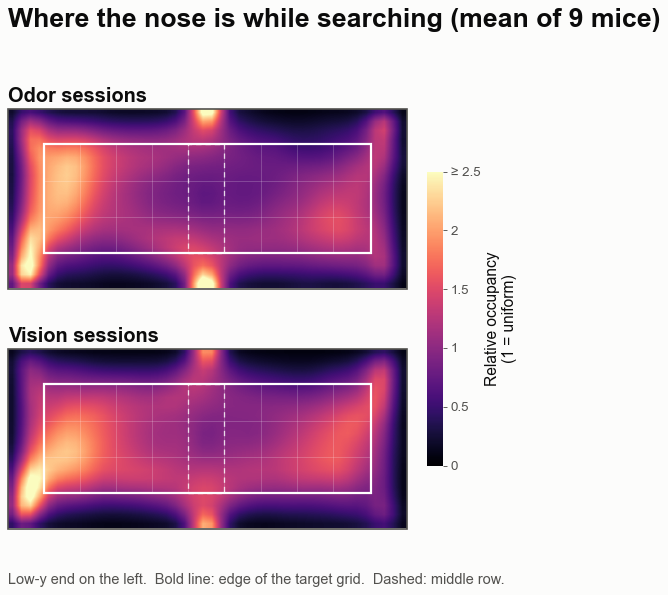

In [3]:
fig = plt.figure(figsize=SLIDE)
axes, cax = arena_axes(fig, 2, 1)
for ax, exp in zip(axes[:, 0], EXPERIMENTS):
    im = show(ax, mean_over_mice(D, ses.experiment == exp), title=f'{EXP_LABEL[exp]} sessions')
colorbar(fig, im, cax(frac=0.7), RELATIVE)
finish(fig, 'Where the nose is while searching (mean of 9 mice)', '01_search_mean')

### By epoch

Each map is scaled to its own epoch's time. Consumption has its own color scale because it is all at the ports.

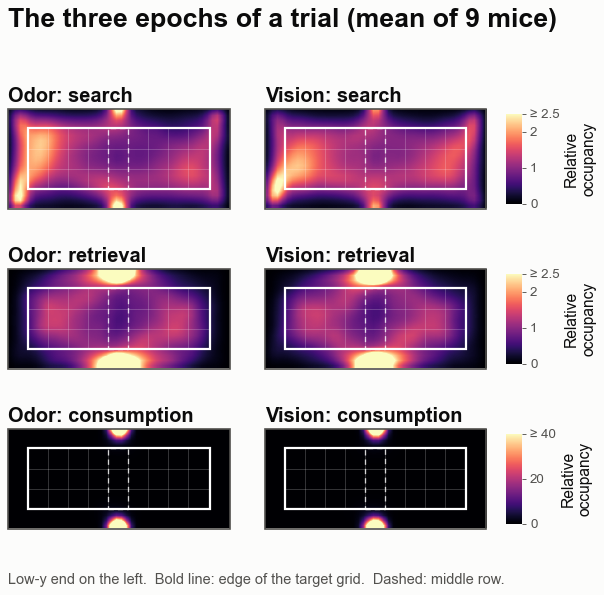

In [4]:
EPOCH_TITLE = {'search': 'Search', 'retrieval': 'Retrieval', 'consumption': 'Consumption'}
EPOCH_VMAX = {'search': VMAX, 'retrieval': VMAX, 'consumption': 40}
fig = plt.figure(figsize=SLIDE)
axes, cax = arena_axes(fig, len(EPOCHS), 2, wgap=0.35, cbar=1.6)
for r, (row, epoch) in enumerate(zip(axes, EPOCHS)):
    for ax, exp in zip(row, EXPERIMENTS):
        im = show(ax, mean_over_mice(smooth(density(maps[epoch])), ses.experiment == exp), vmax=EPOCH_VMAX[epoch],
                  title=f'{EXP_LABEL[exp]}: {EPOCH_TITLE[epoch].lower()}')
    colorbar(fig, im, cax(r, r), 'Relative\noccupancy')
finish(fig, 'The three epochs of a trial (mean of 9 mice)', '02_epochs')

## 2. Every session of every mouse

Rows: mice. Columns: sessions in order. The number in each panel is targets found in that session.

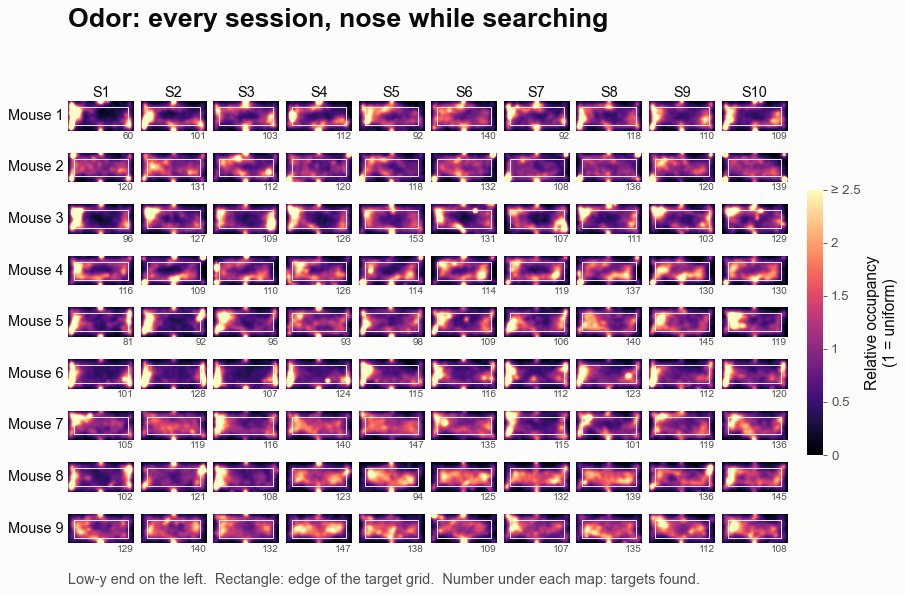

In [5]:
def session_grid(exp):
    fig = plt.figure(figsize=SLIDE)
    axes, cax = arena_axes(fig, len(MICE), 10, top=0.86, bottom=0.07, left=0.1, wgap=0.07, hgap=0.22, cbar=1.3)
    for row, mouse in zip(axes, MICE):
        for n, ax in enumerate(row, start=1):
            hit = ses[(ses.experiment == exp) & (ses.mouse == mouse) & (ses.session_num == n)]
            if len(hit):
                im = ax.imshow(D[hit.index[0]].T, origin='lower', extent=(0, cfg.FRAME_H, 0, cfg.FRAME_W), cmap='magma', vmin=0, vmax=VMAX, interpolation='bilinear')
                ax.add_patch(Rectangle((cfg.CELL_H, cfg.CELL_W), cfg.FRAME_H - 2 * cfg.CELL_H, cfg.FRAME_W - 2 * cfg.CELL_W, fill=False, edgecolor='white', lw=0.8))
                ax.text(1, -0.04, int(hit.finds.iloc[0]), transform=ax.transAxes, ha='right', va='top', fontsize=9, color=MUTED)
            ax.set(xticks=[], yticks=[], xlim=(0, cfg.FRAME_H), ylim=(0, cfg.FRAME_W))
            for side in ax.spines.values():
                side.set_visible(False)
            if mouse == MICE[0]:
                ax.set_title(f'S{n}', fontsize=13, fontweight='normal', loc='center', pad=4)
        row[0].set_ylabel(NAME[mouse], rotation=0, ha='right', va='center', fontsize=13)
    colorbar(fig, im, cax(frac=0.6), RELATIVE)
    finish(fig, f'{EXP_LABEL[exp]}: every session, nose while searching', f'03_sessions_{exp}',
           key='Low-y end on the left.  Rectangle: edge of the target grid.  Number under each map: targets found.')

session_grid('odor')

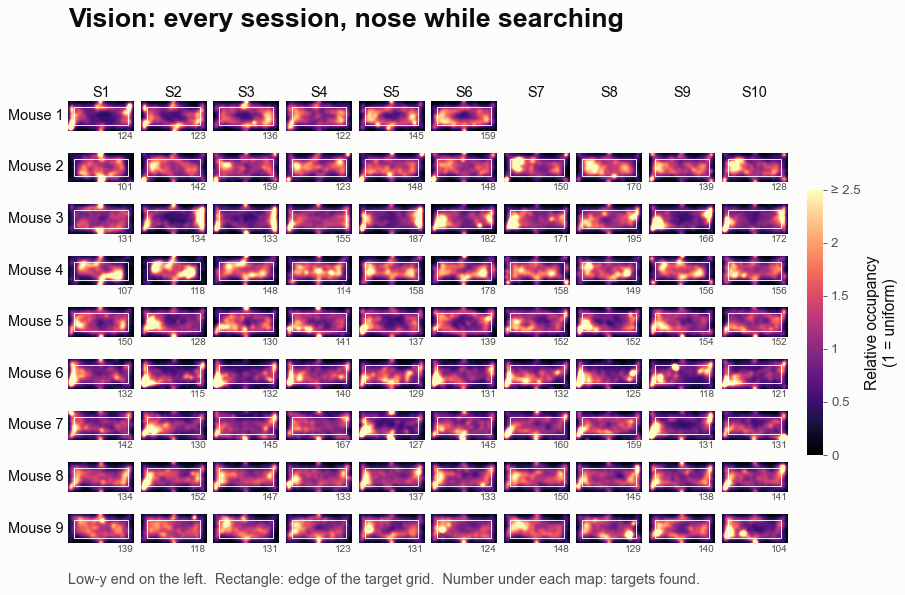

In [6]:
session_grid('vision')

## 3. Do mice differ?

Each mouse's own map (mean over its sessions), then the same map minus the average mouse: red where this mouse spends more time than mice in general, blue where it spends less.

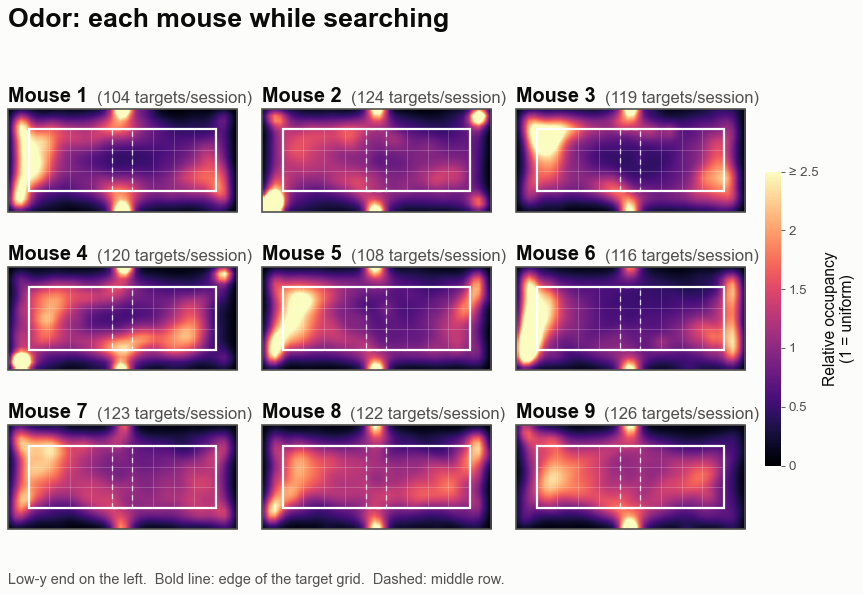

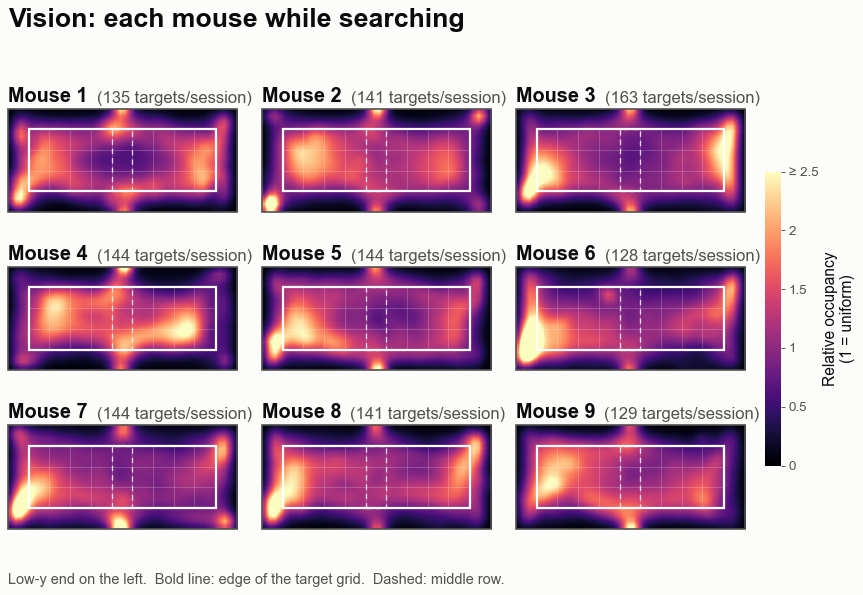

In [7]:
mouse_map = {(exp, m): D[g.index].mean(axis=0) for (exp, m), g in ses.groupby(['experiment', 'mouse'])}
group_map = {exp: np.mean([mouse_map[exp, m] for m in MICE], axis=0) for exp in EXPERIMENTS}

def mouse_grid(get, title, name, diverging=False, vlim=VMAX, label=RELATIVE, exp=None):
    """One panel per mouse, 3 x 3. With `exp`, each title also gives the mouse's mean targets found per session in that experiment."""
    fig = plt.figure(figsize=SLIDE)
    axes, cax = arena_axes(fig, 3, 3, hgap=0.55)
    for ax, m in zip(axes.flat, MICE):
        m_map = get(m)
        if m_map is None:
            ax.axis('off'); continue
        if diverging:
            im = show(ax, m_map, cmap='RdBu_r', vmin=-vlim, vmax=vlim, diverging=True, title=NAME[m])
        else:
            im = show(ax, m_map, vmax=vlim, title=NAME[m])
        if exp is not None:
            name_text = ax.set_title(NAME[m])           # the left title, so the note can sit just after it
            ax.annotate(f'({finds_per_session[exp, m]:.0f} targets/session)', xy=(1, 0), xycoords=name_text,
                        xytext=(8, 0), textcoords='offset points', ha='left', va='bottom', fontsize=15, color=MUTED)
    colorbar(fig, im, cax(frac=0.7), label, clipped='both' if diverging else 'max')
    finish(fig, title, name)

finds_per_session = ses.groupby(['experiment', 'mouse']).finds.mean()
for exp in EXPERIMENTS:
    mouse_grid(lambda m: mouse_map[exp, m], f'{EXP_LABEL[exp]}: each mouse while searching', f'04_mice_{exp}', exp=exp)

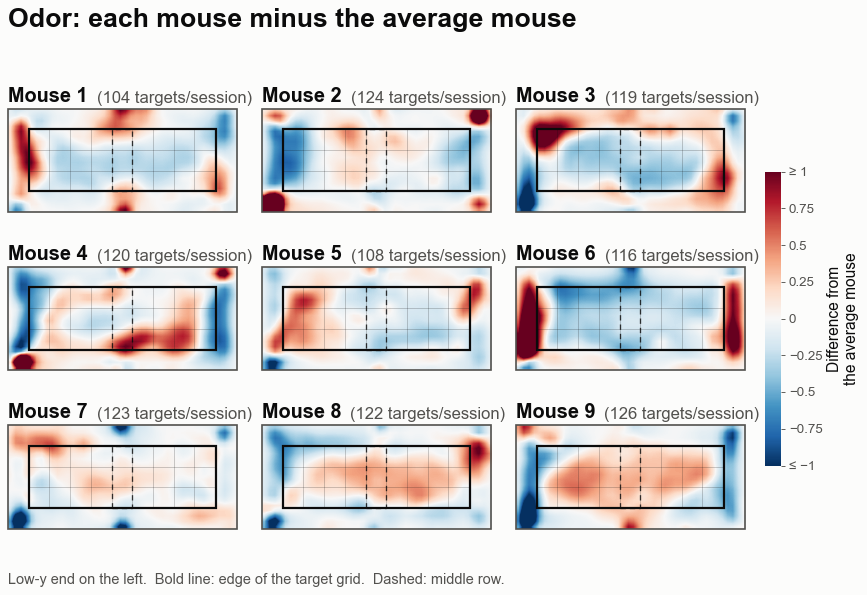

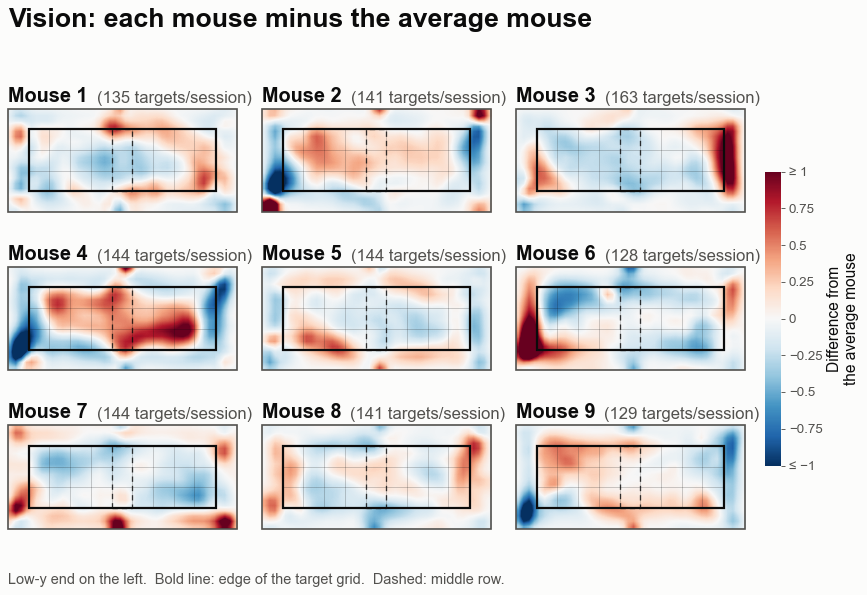

In [8]:
for exp in EXPERIMENTS:
    mouse_grid(lambda m: mouse_map[exp, m] - group_map[exp], f'{EXP_LABEL[exp]}: each mouse minus the average mouse', f'05_mice_vs_average_{exp}',
               diverging=True, vlim=1.0, label='Difference from\nthe average mouse', exp=exp)

**Is a mouse's map its own?** Correlation between every pair of sessions' maps, sorted by mouse, and the odor-vs-vision correlation of each mouse's departure from the average. Computed from the unsmoothed maps, so the values match `occupancy_nose.ipynb`.

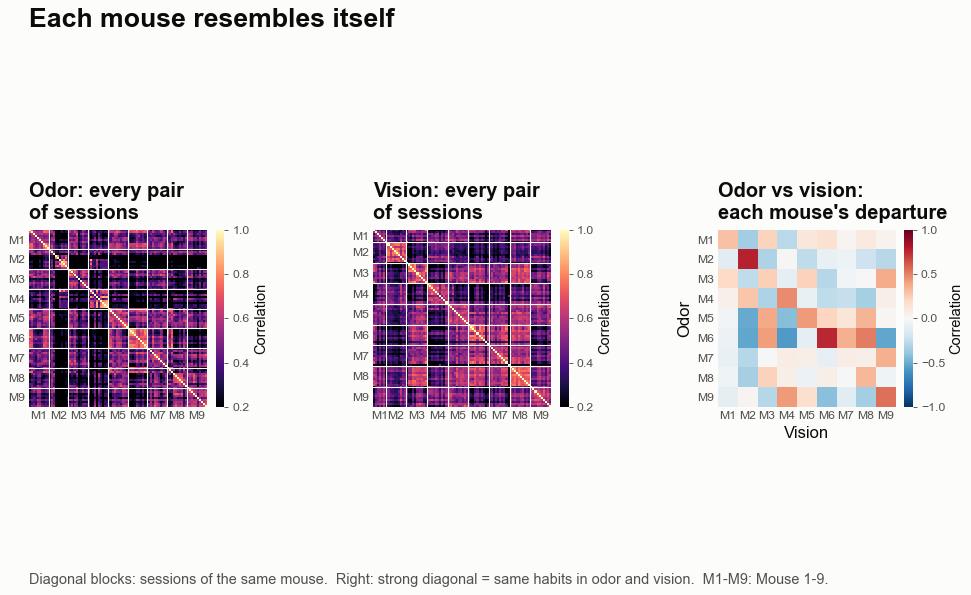

In [9]:
similarity = np.corrcoef(D_raw.reshape(len(D_raw), -1))
raw_mouse_map = {(exp, m): D_raw[g.index].mean(axis=0) for (exp, m), g in ses.groupby(['experiment', 'mouse'])}
raw_group = {exp: np.mean([raw_mouse_map[exp, m] for m in MICE], axis=0) for exp in EXPERIMENTS}
departure = {exp: np.array([(raw_mouse_map[exp, m] - raw_group[exp]).ravel() for m in MICE]) for exp in EXPERIMENTS}
across = np.corrcoef(departure['odor'], departure['vision'])[:len(MICE), len(MICE):]       # [odor mouse, vision mouse]
SHORT = [NAME[m].replace('Mouse ', 'M') for m in MICE]

fig, axes = plt.subplots(1, 3, figsize=SLIDE, gridspec_kw={'wspace': 0.75 * PAD, **padded(top=0.8, bottom=0.14, left=0.05, right=0.9)})
for ax, exp in zip(axes, EXPERIMENTS):
    i = ses.index[ses.experiment == exp].to_numpy()
    im = ax.imshow(similarity[np.ix_(i, i)], cmap='magma', vmin=0.2, vmax=1, interpolation='nearest')
    edges = np.flatnonzero(np.r_[True, ses.mouse[i].to_numpy()[1:] != ses.mouse[i].to_numpy()[:-1], True])
    centres = (edges[:-1] + edges[1:]) / 2 - 0.5
    ax.set(xticks=centres, xticklabels=SHORT, yticks=centres, yticklabels=SHORT)
    ax.set_title(f'{EXP_LABEL[exp]}: every pair\nof sessions', pad=10)
    for e in edges[1:-1]:
        ax.axhline(e - 0.5, color=PAPER, lw=1); ax.axvline(e - 0.5, color=PAPER, lw=1)
im_across = axes[2].imshow(across, cmap='RdBu_r', vmin=-1, vmax=1, interpolation='nearest')
axes[2].set(xticks=range(len(MICE)), xticklabels=SHORT, yticks=range(len(MICE)), yticklabels=SHORT, xlabel='Vision', ylabel='Odor')
axes[2].set_title("Odor vs vision:\neach mouse's departure", pad=10)
for ax, image, label in zip(axes, (im, im, im_across), ('Correlation', 'Correlation', 'Correlation')):
    for side in ax.spines.values():
        side.set_visible(False)
    ax.tick_params(length=0, labelsize=11)
    cb = fig.colorbar(image, cax=ax.inset_axes([1.05, 0, 0.05, 1]))
    cb.set_label(label, fontsize=13); cb.ax.tick_params(labelsize=11); cb.outline.set_visible(False)
finish(fig, 'Each mouse resembles itself', '06_similarity',
       key='Diagonal blocks: sessions of the same mouse.  Right: strong diagonal = same habits in odor and vision.  M1-M9: Mouse 1-9.')

## 4. With experience: last three sessions minus first three

Red: more time there late than early. Blue: less. Mean across mice, then each mouse.

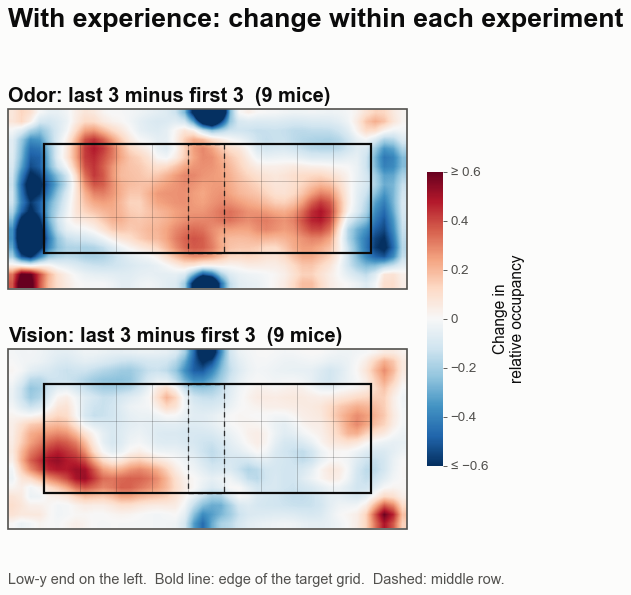

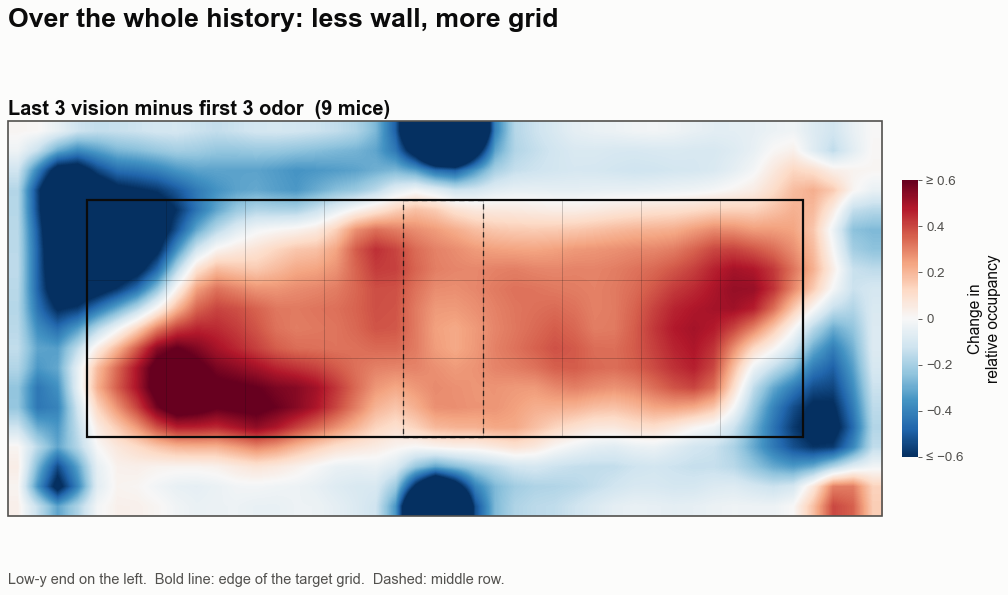

In [10]:
N_ENDS = 3                                         # sessions at each end; every mouse has at least six, so the two never overlap
first = ses.session_num <= N_ENDS
last = ses.session_num > ses.n_sessions - N_ENDS
odor, vision = ses.experiment == 'odor', ses.experiment == 'vision'
CHANGES = {'Odor: last 3 minus first 3': (odor & first, odor & last),
           'Vision: last 3 minus first 3': (vision & first, vision & last),
           'Last 3 vision minus first 3 odor': (odor & first, vision & last)}

def difference_maps(before, after, maps=D):
    """{mouse: after map - before map}, for mice that have both."""
    per_mouse = lambda keep: {m: maps[g.index].mean(axis=0) for m, g in ses[keep].groupby('mouse')}
    a, b = per_mouse(before), per_mouse(after)
    return {m: b[m] - a[m] for m in MICE if m in a and m in b}

def mean_differences(contrasts, title, name, vlim=0.6):
    """Mean across mice of each contrast, stacked; one or two per slide."""
    fig = plt.figure(figsize=SLIDE)
    axes, cax = arena_axes(fig, len(contrasts), 1)
    for ax, (label, (before, after)) in zip(axes[:, 0], contrasts.items()):
        diffs = difference_maps(before, after)
        im = show(ax, np.mean(list(diffs.values()), axis=0), cmap='RdBu_r', vmin=-vlim, vmax=vlim, diverging=True,
                  title=f'{label}  ({len(diffs)} mice)')
    colorbar(fig, im, cax(frac=0.7), CHANGE, clipped='both')
    finish(fig, title, name)

within = {k: CHANGES[k] for k in list(CHANGES)[:2]}
history = {k: CHANGES[k] for k in list(CHANGES)[2:]}
mean_differences(within, 'With experience: change within each experiment', '07_experience_within')
mean_differences(history, 'Over the whole history: less wall, more grid', '07_experience_history')

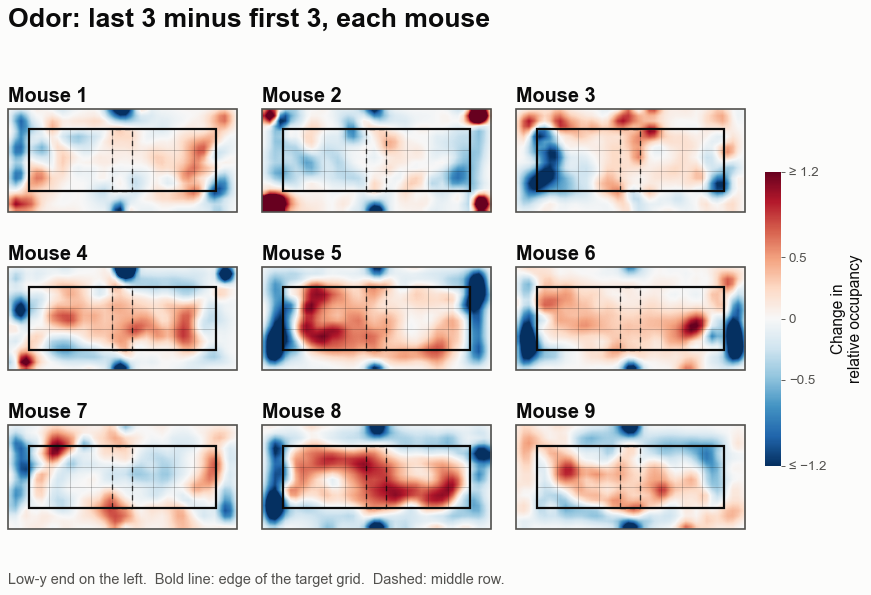

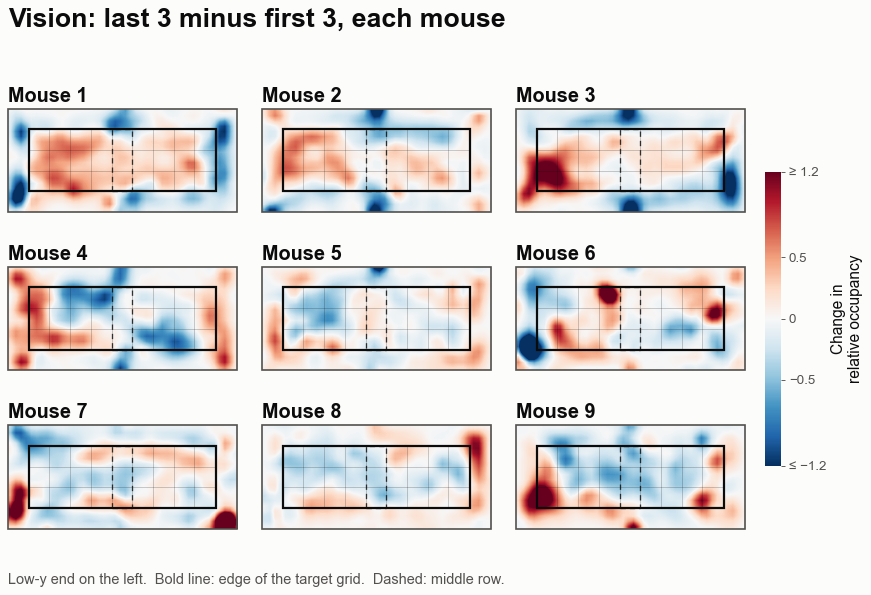

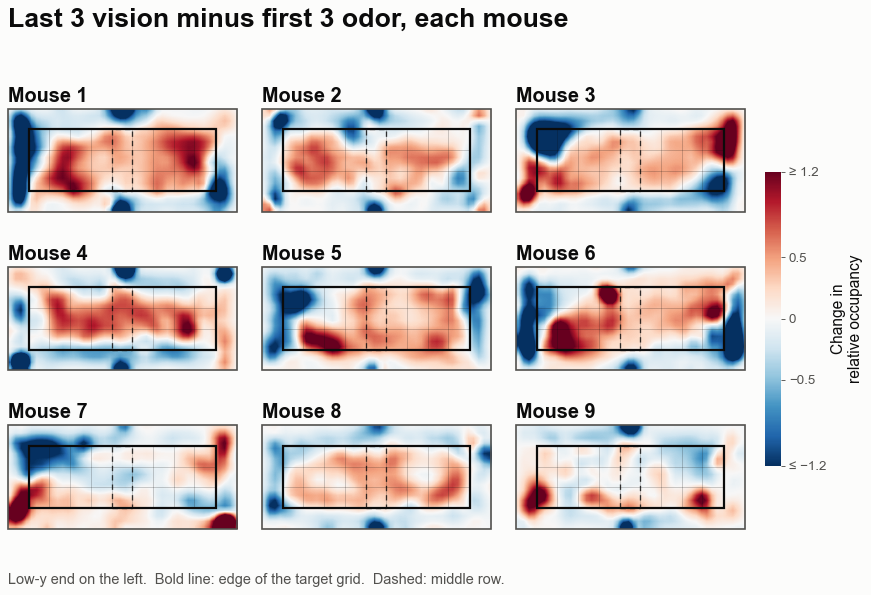

In [11]:
for k, (label, (before, after)) in enumerate(CHANGES.items(), start=1):
    diffs = difference_maps(before, after)
    mouse_grid(diffs.get, f'{label}, each mouse', f'08_experience_mice_{k}', diverging=True, vlim=1.2, label=CHANGE)

**Occupancy against distance from the walls** (ports left out). Computed from the unsmoothed maps, as in `occupancy_nose.ipynb`. Bands: mean ± SEM across mice.

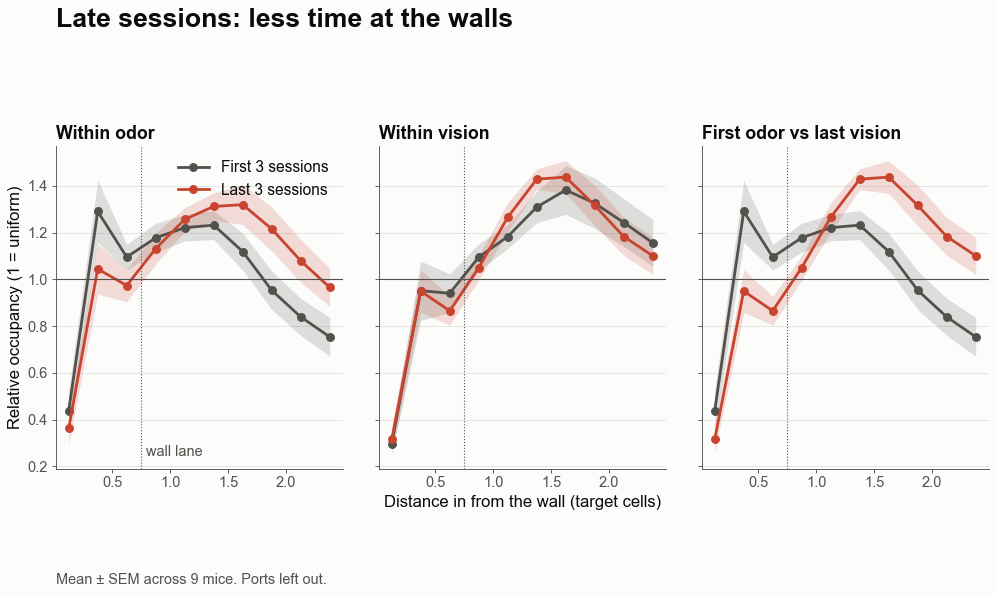

In [12]:
XX, YY = np.meshgrid(xc, yc)
pooled = density(sum(maps.values()).sum(axis=0))
reach_x, reach_y = xc[pooled.mean(axis=0) > 0.05], yc[pooled.mean(axis=1) > 0.05]
half_x, half_y = np.diff(X_EDGES)[0] / 2, np.diff(Y_EDGES)[0] / 2
REACH = dict(x0=reach_x.min() - half_x, x1=reach_x.max() + half_x, y0=reach_y.min() - half_y, y1=reach_y.max() + half_y)
wall_dist = np.minimum(np.minimum(XX - REACH['x0'], REACH['x1'] - XX), np.minimum(YY - REACH['y0'], REACH['y1'] - YY))
LANE = 0.75 * cfg.CELL_W
DIST_EDGES = np.arange(0, (REACH['x1'] - REACH['x0']) / 2 + 1, cfg.CELL_W / 4)
band = np.where(ports | (wall_dist <= 0), -1, np.digitize(wall_dist, DIST_EDGES) - 1)
mid_dist = (DIST_EDGES[:-1] + DIST_EDGES[1:]) / 2 / cfg.CELL_W

def wall_profile(keep):
    """Per mouse (rows), occupancy by distance from the nearest wall: mean density of the bins in each distance band."""
    return pd.DataFrame({m: [D_raw[g.index].mean(axis=0)[band == k].mean() for k in range(len(DIST_EDGES) - 1)]
                         for m, g in ses[keep].groupby('mouse')}).T

PROFILE_TITLE = ['Within odor', 'Within vision', 'First odor vs last vision']
fig, axes = plt.subplots(1, len(CHANGES), figsize=SLIDE, sharey=True, gridspec_kw={'wspace': 0.1 * PAD, **padded(top=0.8, bottom=0.17, left=0.08, right=0.98)})
for ax, label, (before, after) in zip(axes, PROFILE_TITLE, CHANGES.values()):
    for keep, color, name in ((before, MUTED, 'First 3 sessions'), (after, '#c8442f', 'Last 3 sessions')):
        p = wall_profile(keep)
        ax.fill_between(mid_dist, p.mean() - p.sem(), p.mean() + p.sem(), color=color, alpha=0.18, lw=0)
        ax.plot(mid_dist, p.mean(), color=color, lw=2.5, marker='o', ms=7, label=name)
    ax.axvline(LANE / cfg.CELL_W, color=MUTED, lw=1, ls=':'); ax.axhline(1, color=MUTED, lw=1)
    ax.set_title(label, fontsize=16)
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[1].set_xlabel('Distance in from the wall (target cells)')
axes[0].set_ylabel('Relative occupancy (1 = uniform)')
axes[0].legend(loc='upper right')
axes[0].text(LANE / cfg.CELL_W + 0.04, 0.04, 'wall lane', fontsize=13, color=MUTED, transform=axes[0].get_xaxis_transform())
finish(fig, 'Late sessions: less time at the walls', '09_wall_profile', key='Mean ± SEM across 9 mice. Ports left out.')

## 5. Good sessions minus poor sessions

For each mouse, its three sessions with the most targets found minus its three with the fewest.

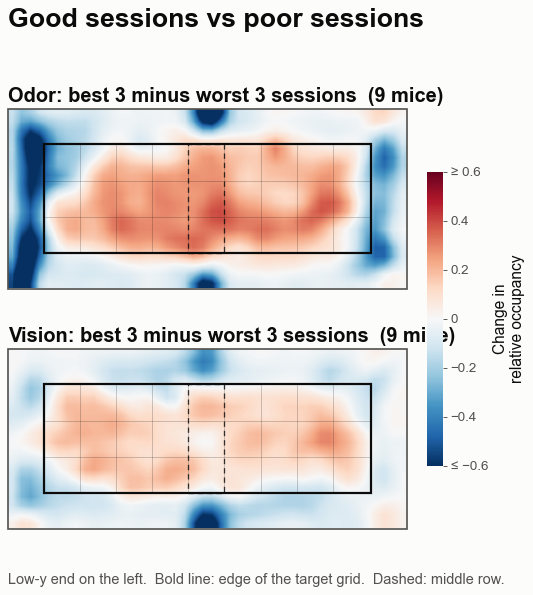

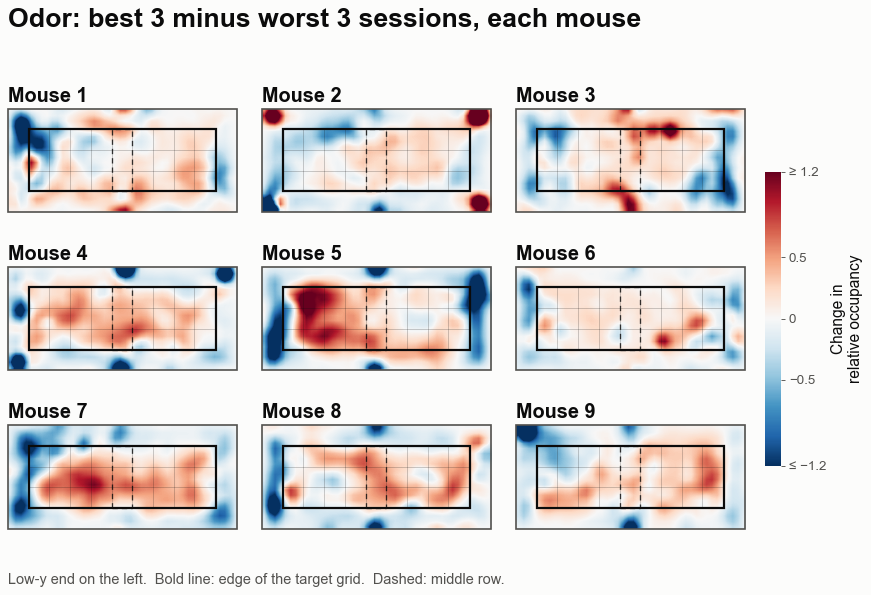

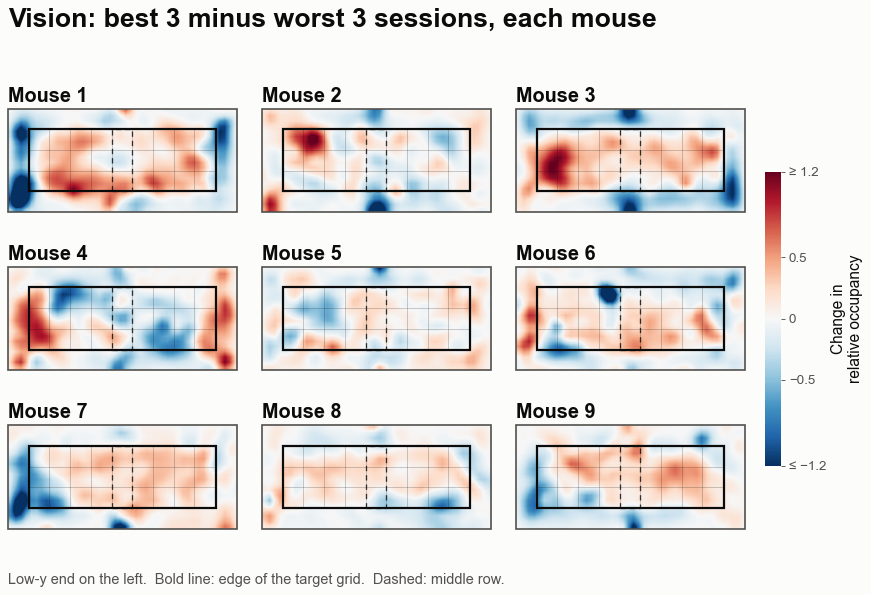

In [13]:
rank = ses.groupby(['experiment', 'mouse']).finds.rank(method='first')
best = rank > ses.n_sessions - 3
worst = rank <= 3
QUALITY = {f'{EXP_LABEL[exp]}: best 3 minus worst 3 sessions': ((ses.experiment == exp) & worst, (ses.experiment == exp) & best) for exp in EXPERIMENTS}

mean_differences(QUALITY, 'Good sessions vs poor sessions', '10_quality_mean', vlim=0.6)
for k, (label, (before, after)) in enumerate(QUALITY.items(), start=1):
    diffs = difference_maps(before, after)
    mouse_grid(diffs.get, f'{label}, each mouse', f'11_quality_mice_{k}', diverging=True, vlim=1.2, label=CHANGE)